# EM algorithm for unsupervised and semi-supervised learning

# 1. EM algorithm for Gaussian mixtures

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import multivariate_normal
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans


We have worked out the calculations for a Gaussian mixture with $d = 1$. Let’s now do for $d = 2$.

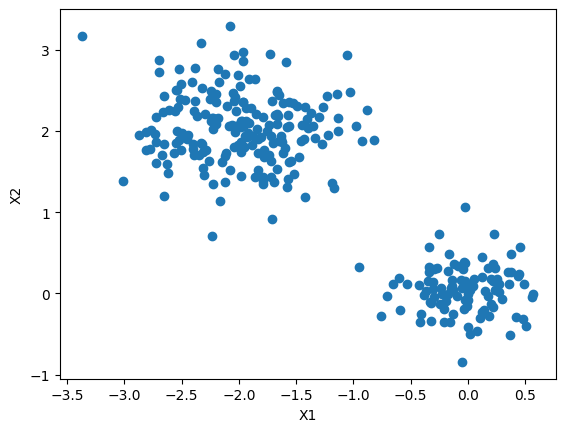

In [ ]:
X1 = np.random.multivariate_normal(
    mean=[0, 0],
    cov=0.1 * np.eye(2),
    size=100
)

X2 = np.random.multivariate_normal(
    mean=[-2, 2],
    cov=0.2 * np.eye(2),
    size=200
)

X = np.vstack((X1, X2))

plt.scatter(X[:, 0], X[:, 1])
plt.xlabel("X1")
plt.ylabel("X2")
plt.show()

## Question 1.1.

Which is the model? Which are the parameters of the EM algorithm (dimensions, constraints)?

## Question 1.2.

How to initialize the algorithm? Create a function for the initialization.

*Tip: You will need the posterior probabilities in the following steps. You can create an object here to store them.*

## Question 1.3.

What are the steps of the EM algorithm? Implement the algorithm.

* At each iteration, create an option in your function in order to plot the data using a different color for each group, based on the estimated posterior probabilities.
* Compute the log-likelihood at each iteration and store it.

You can take this structure for the code.

In [ ]:
def EMalgo(X, K=2, n_iter=50, plot=False):

    n = X.shape[0]
    d = X.shape[1]

    # Initialization
    P, prop, mu, Sigma = initialization_EM(X, K=K)

    loglik = []

    for it in range(n_iter):

        # E-step
        ...

        if plot:
            ...

        # M-step
        ...

        # Log-likelihood
        ...
        loglik_it = ...
        loglik.append(loglik_it)


    return {
        "P": P,
        "prop": prop,
        "mu": mu,
        "Sigma": Sigma,
        "loglik": loglik
    }

## Question 1.4.

Apply the EM algorithm.
* Plot the data at each iteration.
* Verify that the log-likelihood increases until convergence.

## Question 1.5.

How to select $K$, the number of groups, which is unknown in practice? Modify the function `EMalgo` to compute the BIC score. And select $K$.

The BIC score is defined as follows:
$$\textrm{BIC}=0.5 *b \log(n) - \hat{L}_c,$$
with
* $b$: the number of parameters estimated by the model
* $n$: the number of samples
* $\hat{L}_c$: the maximized value of the log-likelihood function

In practice, to compute $\hat{L}_c$ here, you can just take the last iteration of the EM algorithm.


## Question 1.6.

Use the function `GaussianMixture` of the scikit-learn module `sklearn.mixture` and compare the results. You can also compare the results with the k-mean algorithm using the function `KMeans` of the scikit-learn module `sklearn.cluster`.

## Question 1.7.

Apply the EM algorithm for the following data (more difficult). In particular, test whether BIC selects the correct value of $K$ in this case. Increase the parameter `cov_param` to make the data difficult to separate.